# When Exact Zero Becomes Huge

**A workshop on generic numerical programming in Julia @ Julia4HPC, Fréjus.**

**15 October 2026, Oskar Laverny**

How can a mathematically exact algorithm return a wrong answer when its number type changes? We will explore this question by deriving a nasty recurrence, implementing it in Julia, and testing it with `Float64`, `BigFloat`, and `MultiFloats.jl`.

The notebook combines explanations, executable experiments, performance measurements, and validation. Work through the cells in order: make a prediction, run the experiment, then compare the result with the mathematical oracle. The environment is pinned in `Project.toml` and `Manifest.toml`.

In [1]:
using BenchmarkTools
using Distributions
using InteractiveUtils
using Metaheuristics
using MultiFloats
using Plots
using PrettyTables
using Printf
using Random
using Statistics
using Test

@assert VERSION >= v"1.10"
@assert pkgversion(MultiFloats) >= v"3"
"Julia $VERSION; MultiFloats $(pkgversion(MultiFloats))"

"Julia 1.13.0; MultiFloats 3.3.2"

## I.1 · The numerical question

This workshop studies numerical genericity through a concrete scientific computation: matching Laguerre coefficients to fit a sum of independent gamma variables to data. The model requires high-order tilted moments, computed from cumulants with Faà di Bruno's recurrence. Although the recurrence is exact, its terms grow rapidly and cancel, so changing Julia's number type can change the computed result dramatically.

> What must an algorithm preserve when its number type changes, and how can we tell whether its final scientific result is trustworthy?

We will derive and implement the recurrence, compare `Float64`, `BigFloat`, and fixed-precision `MultiFloat` arithmetic, then examine a high-dimensional particle-swarm fit. The aim is not only to obtain a small objective value, but also to validate the fitted distribution independently.

A type parameter is not, by itself, a guarantee of numerical genericity. We will make the missing obligations concrete through executable experiments and independent checks.

### Two small reminders on type stability

The following function can produce type stable or type unstable methods depending on the passed arguments: 

In [2]:
function potentially_unstable(x::Vector{T}) where {T}
    y = first(x)
    return y > zero(T) ? y : 0.0
end

@code_warntype potentially_unstable(Float32[1])
typeof(potentially_unstable(Float32[1]))  # Float32
typeof(potentially_unstable(Float32[-1])) # Float64

MethodInstance for potentially_unstable(::Vector{Float32})
  from potentially_unstable(x::Vector{T}) where T @ Main c:\Users\lrnv\Documents\anf_frejus_julia\jl_notebook_cell_df34fa98e69747e1a8f8a730347b8e2f_W4sZmlsZQ==.jl:1
Static Parameters
  T = Float32
Arguments
  #self#::Core.Const(Main.potentially_unstable)
  x::Vector{Float32}
Locals
  y::Float32
Body::Union{Float32, Float64}
1 ─ %1  = Main.first::Core.Const(first)
│         (y = (%1)(x))
│   %3  = Main.:>::Core.Const(>)
│   %4  = y::Float32
│   %5  = Main.zero::Core.Const(zero)
│   %6  = $(Expr(:static_parameter, 1))::Core.Const(Float32)
│   %7  = (%5)(%6)::Core.Const(0.0f0)
│   %8  = (%3)(%4, %7)::Bool
└──       goto #3 if not %8
2 ─ %10 = y::Float32
└──       return %10
3 ─       return 0.0



Float64

Hence, type stability is not a property of the **function** but only of the **method instances**, which include the types of the trully passed arguments. 

The two next function calls are type stable. Still, the returned type is not the same as the inputed type: a type stable operation does NOT mean an operation that will preserve input types !

In [3]:

function widened_accumulation(x::Vector{T}) where {T}
    acc = 0.0
    for xi in x
        acc += xi
    end
    return acc
end
@code_warntype widened_accumulation(Float32[1, 2])
typeof(widened_accumulation(Float32[1, 2])) # Float64

MethodInstance for widened_accumulation(::Vector{Float32})
  from widened_accumulation(x::Vector{T}) where T @ Main c:\Users\lrnv\Documents\anf_frejus_julia\jl_notebook_cell_df34fa98e69747e1a8f8a730347b8e2f_W6sZmlsZQ==.jl:2
Static Parameters
  T = Float32
Arguments
  #self#::Core.Const(Main.widened_accumulation)
  x::Vector{Float32}
Locals
  @_3::Union{Nothing, Tuple{Float32, Int64}}
  acc::Float64
  xi::Float32
Body::Float64
1 ─       (acc = 0.0)
│   %2  = x::Vector{Float32}
│         (@_3 = Base.iterate(%2))
│   %4  = @_3::Union{Nothing, Tuple{Float32, Int64}}
│   %5  = (%4 === nothing)::Bool
│   %6  = Base.not_int(%5)::Bool
└──       goto #4 if not %6
2 ┄ %8  = @_3::Tuple{Float32, Int64}
│         (xi = Core.getfield(%8, 1))
│   %10 = Core.getfield(%8, 2)::Int64
│   %11 = Main.:+::Core.Const(+)
│   %12 = acc::Float64
│   %13 = xi::Float32
│         (acc = (%11)(%12, %13))
│         (@_3 = Base.iterate(%2, %10))
│   %16 = @_3::Union{Nothing, Tuple{Float32, Int64}}
│   %17 = (%16 === 

Float64

Be aware that Julia widen types in a lot of standard operations (additions, multiplications, etc..)

## I.2 · The scientific model

The scientific example is to estimate the distribution of a sum of independent gamma variables from data:

$$X \sim \mathcal G_{n}(\bm\alpha, \bm\theta) \iff X = \sum_{i=1}^n X_i \text{ where } X_i \sim \Gamma(\alpha_i, \theta_i).$$

A sum of independent gamma variables does not in general have a gamma density; its density can be expressed by convolution or transform methods, but direct likelihood evaluation can be inconvenient. Here we use a moment-matching approach with the orthonormal Laguerre basis $\Phi = \left\{\phi_k: k\in \mathbb N\right\}$, defined by

$$\phi_k(x) = \sqrt{2} \sum_{j=0}^k \binom{k}{j} \frac{(-2x)^j}{j!} e^{-x}.$$

From a dataset $\bm x = \left(x_1,...,x_N\right)$, we can compute empirical Laguerre coefficients

$$a_k(\bm x) = \frac{1}{N}\sum\limits_{i=1}^N \phi_k(x_i),$$

and theoretical ones as

$$a_k(\bm\alpha, \bm\theta)=\mathbb E[\phi_k(X)] = \sqrt{2} \sum_{j=0}^k \binom{k}{j} \frac{(-2)^j}{j!} \mathbb E[X^j e^{-X}].$$

We match them with the loss

$$L_K(\bm\alpha, \bm\theta; \bm x) = \sum\limits_{k=0}^{K-1} \left(a_k(\bm\alpha, \bm\theta) - a_k(\bm x)\right)^2.$$

### Computing the tilted moments

The remaining numerical task is to compute the tilted moments $\mu_k$ from the parameters $\bm\alpha,\bm\theta$:

$$\mu_k = \mathbb E[X^k e^{-X}].$$

Note that $\mu_k = M^{(k)}(-1)$, where $M(t) = \mathbb E[e^{tX}]$ is the moment-generating function. For independent gamma variables parameterized by shape and scale, the cumulant-generating function is

$$K(t) = \ln M(t) = \ln \mathbb E[e^{tX}] = - \sum\limits_{i=1}^n \alpha_i \ln(1-t\theta_i), \qquad t < \min_i \theta_i^{-1}.$$

Let $\bm\kappa$ denote the derivatives of $K$ evaluated at $t=-1$. The loss is computed through the path

$$\text{parameters } (\bm\alpha, \bm\theta) \longrightarrow \text{cumulants } \bm\kappa \longrightarrow \text{moments } \bm\mu \longrightarrow \text{Laguerre coefficients } \bm a \longrightarrow \text{loss } L_K.$$

Faà di Bruno provides the recursive bridge from cumulants (derivatives of $K$) to tilted moments (derivatives of $M$), as derived in the next section.

### First, isolate the numerical issue

We first isolate that step: the numerical issue we want to study is already present without the full setup. We return to the full setup in Part III.

Remark: High-order Taylor-mode automatic differentiation also propagates many derivative coefficients through recursive operations. TaylorDiff.jl does this with Taylor polynomials through operator overloading; TaylorSeries.jl works with polynomial expansions. The computational pattern is related, though the implementations differ. Sources: [TaylorDiff.jl](https://github.com/JuliaDiff/TaylorDiff.jl) · [TaylorSeries.jl](https://juliadiff.org/TaylorSeries.jl/stable/userguide/) · F. M. Miatto, [Recursive multivariate derivatives](https://arxiv.org/abs/1911.11722).

## I.3 Our toy version

For $M(x)=\exp(K(x))$, Faà di Bruno gives

$$M^{(n)}(x)=\sum_{k=0}^{n-1}\binom{n-1}{k}M^{(k)}(x)K^{(n-k)}(x).$$

Take the special case $n=1$ and $\alpha_1=\theta_1=1$, so $X$ is an exponential random variable with unit rate. Then

$$K(x)=\log(1+x).$$

Since $M(x)=1+x$, its derivatives at zero are $[1,1,0,\ldots,0]$. However, for $n\ge1$,

$$K^{(n)}(0)=(-1)^{n-1}(n-1)!.$$

The recurrence combines increasingly large alternating quantities to produce exact zero.

**Think:** Before running the experiment, predict how finite-precision arithmetic might affect the result at order 60.

## I.4 Implementing the recurrence

As you read the implementation, connect each line to the recurrence.

Remark that exact combinatorics enter as type `T`, storage follows the input element type, and accumulators starts at `zero(T)`. This is the kind of care you must input in your julia code to make it not only type-stable, but type-preserving as well. 

In [4]:
function binomial_table(::Type{T}, N::Integer) where {T}
    B = zeros(T, N, N)
    for n in 1:N, k in 0:(n - 1)
        B[n, k + 1] = T(binomial(big(n - 1), big(k)))
    end
    return B
end

exp_derivatives(κ::AbstractVector{T}, μ₀::T) where {T} = exp_derivatives(κ, binomial_table(T, length(κ) - 1), μ₀)
function exp_derivatives(κ::AbstractVector{T}, B, μ₀::T) where {T}
    # This is the faa-di-bruno formula in one dimension, computing derivatives of M from derivatives of K.
    μ = similar(κ)
    μ[1] = μ₀

    for n in 1:(length(κ) - 1)
        μ[n + 1] = zero(T)
        for k in 0:(n - 1)
            μ[n + 1] += B[n, k + 1] * μ[k + 1] * κ[n - k + 1]
        end
    end

    return μ
end

function log1p_derivatives(::Type{T}, N::Integer) where {T}
    # This is the reverse operation (Faa Di Bruno gives a bijection)
    N >= 0 || throw(ArgumentError("N must be non-negative"))

    κ = Vector{T}(undef, N + 1)
    κ[1] = zero(T)
    for n in 1:N
        κ[n + 1] = T((-1)^(n - 1) * factorial(big(n - 1)))
    end
    return κ
end

# Two helpers to diagnoe our issues: 
cancellation_experiment(::Type{T}, N::Integer) where {T} = exp_derivatives(log1p_derivatives(T, N), one(T))
function first_nonzero_order(μ::AbstractVector)
    index = findfirst(!iszero, @view μ[3:end])
    return isnothing(index) ? nothing : index + 1
end

first_nonzero_order (generic function with 1 method)

### What the code must preserve

- `Vector{T}` and `similar` keep the result in the input arithmetic.
- `zero(T)` and `one(T)` make the initial values explicit.
- The binomial coefficient is converted from an exact `BigInt` into `T`.
- The loop follows the mathematical recurrence directly.

Together these choices make the arithmetic model explicit; the tests later in the notebook check that the expected behavior holds.

## I.5 · Float64: the first result

The exact oracle is zero for every derivative from order two onward. Before running the next cells, predict the first order at which `Float64` might return a non-zero value. Then compare your prediction with the computed values.

In [5]:
values64 = cancellation_experiment(Float64, 60)

61-element Vector{Float64}:
  1.0
  1.0
  0.0
  0.0
  0.0
  0.0
  0.0
  0.0
  0.0
  0.0
  ⋮
  1.5603206498478474e49
 -7.957635314224024e50
  4.1379703633964924e52
 -2.1931242926001406e54
  1.1842871180040757e56
 -6.51357914902242e57
  6.792512609381215e60
 -1.4363592466643603e61
  8.33088363065329e62

In [6]:

(first_failure=first_nonzero_order(values64), order_60=values64[end], exact_order_60=0.0)

(first_failure = 29, order_60 = 8.33088363065329e62, exact_order_60 = 0.0)

**The algorithm is exact. The arithmetic is not.**

The first non-zero derivative appears at order 29. At order 60 the residual is about $8.33\times10^{62}$, even though the exact answer is zero. This is catastrophic cancellation, not overflow: the exponent range still accommodates the individual values, but significant digits are lost while subtracting large, nearly equal terms.

How does the scale of this residual compare with the exact result? What does that tell you about the role of precision?

### Exact arithmetic: is the recurrence itself wrong?

The large residual could come from a faulty recurrence or from finite-precision arithmetic. Test the same algorithm with `Rational{BigInt}`: integer numerators and denominators preserve every operation exactly. Compare the exact result with the `Float64` output.

In [7]:
exact_values = cancellation_experiment(Rational{BigInt}, 60)
@assert all(iszero, exact_values[3:end])

The exact result confirms that the recurrence is mathematically consistent; the `Float64` residual comes from rounded arithmetic. Exact rationals are useful as an oracle, but their integer numerators can grow in size. They answer a correctness question, not necessarily a performance one.

**Think:** What do yo uthink are the drawbacks of Rational{BigInt} ? Hint: there is more than one ;)

## I.6 · The numerical genericity contract (watch for silent promotions)

Now that we saw how the problem might manifest itself, here is a few guidelines on how to avoid it. 

A generic numerical algorithm must ensure:

1. Constants and combinatorial coefficients enter the intended arithmetic.
2. Containers and accumulators preserve that arithmetic.
3. Intermediate operations do not trigger an unintended promotion.
4. Results are checked against an independent oracle.

Note that `where {T}` proves none of these. Type stability is necessary, but does not guarantee that the chosen arithmetic is the one we intended.

In [8]:
b_bad = binomial(big(10), big(5))
b_good = Float64(b_bad)
(bad_expression=typeof(b_bad * one(Float64)),
 good_expression=typeof(b_good * one(Float64)))

(bad_expression = BigFloat, good_expression = Float64)

The first expression promotes `BigInt × Float64` to `BigFloat`; converting the coefficient first keeps the expression in `Float64`. This is a concrete example of code that looks generic while silently changing its arithmetic model.

Promotion rules generally widen mixed expressions according to Julia's promotion table. To select another arithmetic model, convert values explicitly before combining them.

# Part II · Precision and representation

How should precision enter a numerical program? We will compare runtime precision, precision encoded in a type, and the consequences for performance.

## II.1 · BigFloat: precision as runtime state

Compare two ways of constructing the decimal `0.1`. Predict whether increasing precision after construction can recover digits already lost.

In [9]:
(from_float=BigFloat(0.1), from_decimal=big"0.1")

(from_float = 0.1000000000000000055511151231257827021181583404541015625, from_decimal = 0.1000000000000000000000000000000000000000000000000000000000000000000000000000002)

High precision cannot recover information discarded before construction. Precision must be selected before values are created. It is runtime context for `BigFloat`, not a distinct concrete Julia type.

In [10]:
type_at_53 = setprecision(53) do
    typeof(BigFloat(1))
end
type_at_256 = setprecision(256) do
    typeof(BigFloat(1))
end
(type_at_53, type_at_256, type_at_53 === type_at_256)

(BigFloat, BigFloat, true)

Repeat the order-60 computation while changing only the working precision. How many bits are needed to recover exact zero in this example?

### Comparing precisions

The `BigFloat` type remains the same across the ladder; only the runtime precision changes. More bits postpone the loss of cancellation. The 209- and 256-bit runs should recover exact zero at order 60. Because `BigFloat` uses dynamic MPFR values, its allocation and hardware costs differ from fixed-size number types.

In [11]:
precision_results = [
    setprecision(bits) do
        values = cancellation_experiment(BigFloat, 60)
        (bits, first_nonzero_order(values), values[end])
    end
    for bits in (53, 105, 157, 209, 256)
]
precision_table_data = hcat(([row[i] for row in precision_results] for i in 1:3)...)
pretty_table(precision_table_data;
    column_labels=["Precision (bits)", "First failure", "Residual at order 60"],
    backend=:html)

Precision (bits),First failure,Residual at order 60
53.0,29.0,8.3308836306532898e62
105.0,43.0,-5.79441093015254182004263451246603e48
157.0,54.0,-7.903561689897431560488849768448e30
209.0,nothing,0.0
256.0,nothing,0.0


## II.2 · MultiFloats: precision as a type

Now keep the algorithm and order fixed while changing the concrete type. Predict which types will preserve the exact zero through order 60.

In [12]:
multifloat_types = (Float64x1, Float64x2, Float64x3, Float64x4)
multifloat_results = [
    let values = cancellation_experiment(T, 60)
        (string(T), precision(T), first_nonzero_order(values), values[end])
    end
    for T in multifloat_types
]
multifloat_table_data = hcat(([row[i] for row in multifloat_results] for i in 1:4)...)
pretty_table(multifloat_table_data;
    column_labels=["Type", "Bits", "First failure", "Residual at order 60"],
    backend=:html)

Type,Bits,First failure,Residual at order 60
"MultiFloat{Float64, 1}",53,29,8.33088363065329e62
"MultiFloat{Float64, 2}",105,38,-4.35600350020373701714402647296167e46
"MultiFloat{Float64, 3}",157,52,-2.412014637662021026207840075776e30
"MultiFloat{Float64, 4}",209,nothing,0.0


Compare your prediction with the measurements. One additional limb changes the answer from a large residual to exact zero. Note that `isbits(Float64xX)` is true !

## II.3 · What the compiler sees

The limb count is part of each concrete type. Inspect the representation and the inferred return type in the next cells. What does specialization tell us about the output container, and what does it not tell us about numerical accuracy?

In [13]:
@code_warntype cancellation_experiment(Float64x3, 10)

MethodInstance for cancellation_experiment(::Type{MultiFloat{Float64, 3}}, ::Int64)
  from cancellation_experiment(::Type{T}, N::Integer) where T @ Main c:\Users\lrnv\Documents\anf_frejus_julia\jl_notebook_cell_df34fa98e69747e1a8f8a730347b8e2f_X14sZmlsZQ==.jl:38
Static Parameters
  T = MultiFloat{Float64, 3}
Arguments
  #self#::Core.Const(Main.cancellation_experiment)
  _::Core.Const(MultiFloat{Float64, 3})
  N::Int64
Body::Vector{MultiFloat{Float64, 3}}
1 ─ %1 = Main.exp_derivatives::Core.Const(Main.exp_derivatives)
│   %2 = Main.log1p_derivatives::Core.Const(Main.log1p_derivatives)
│   %3 = $(Expr(:static_parameter, 1))::Core.Const(MultiFloat{Float64, 3})
│   %4 = (%2)(%3, N)::Vector{MultiFloat{Float64, 3}}
│   %5 = Main.one::Core.Const(one)
│   %6 = $(Expr(:static_parameter, 1))::Core.Const(MultiFloat{Float64, 3})
│   %7 = (%5)(%6)::Core.Const(MultiFloat{Float64, 3}((1.0, 0.0, 0.0)))
│   %8 = (%1)(%4, %7)::Vector{MultiFloat{Float64, 3}}
└──      return %8

::Core.Const(MultiFloat{Fl

The inferred return type is `Vector{MultiFloat{Float64, 3}}`: storage stays concrete and the limb count is known during compilation. Type stability is necessary, but does not prove numerical stability. The algorithm's operational contract includes conversion of exact integers into `T`, `zero`, `one`, addition, multiplication, stable typed storage, and enough exponent range.

## II.4 · Precision, time, and memory

The timed kernel excludes input preparation and includes warmed-up compilation. Compare the benchmark measurements below across latency, allocations, and representation size. These are distinct axes; the best choice depends on the workload and its constraints.

In [14]:
benchmark_types = (Float64x1, Float64x2, Float64x3, Float64x4, BigFloat)
benchmark_inputs = map(benchmark_types) do T
    κ = log1p_derivatives(T, 60)
    B = binomial_table(T, 60)
    (; T, κ, B, μ₀=one(T))
end

input = benchmark_inputs[4]
@benchmark exp_derivatives($(input.κ), $(input.B), $(input.μ₀)) samples=20 evals=1

BenchmarkTools.Trial: 20 samples with 1 evaluation per sample.
 Range (min … max):  270.500 μs … 284.700 μs  ┊ GC (min … max): 0.00% … 0.00%
 Time  (median):     270.700 μs               ┊ GC (median):    0.00%
 Time  (mean ± σ):   271.955 μs ±   3.289 μs  ┊ GC (mean ± σ):  0.00% ± 0.00%

  █                                                              
  █▃▃▁▁▁▁▁▁▄▁▁▁▁▁▁▃▁▁▃▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▃ ▁
  270 μs           Histogram: frequency by time          285 μs <

 Memory estimate: 2.02 KiB, allocs estimate: 2.

In [15]:
benchmark_results = NamedTuple[]
for input in benchmark_inputs
    trial = @benchmark exp_derivatives($(input.κ), $(input.B), $(input.μ₀)) samples=100 evals=1
    estimate = median(trial)
    push!(benchmark_results,
          (type=input.T, time_ns=estimate.time, memory_bytes=estimate.memory,
           allocations=estimate.allocs, bytes_per_value=sizeof(input.μ₀)))
end

benchmark_table_rows = [
    (row.type === BigFloat ? "BigFloat" : "Float64x$(row.type.parameters[2])",
     @sprintf("%.2f", row.time_ns / 1e3),
     @sprintf("%.2f", row.memory_bytes / 1024),
     row.allocations,
     row.bytes_per_value)
    for row in benchmark_results
]
benchmark_table_data = hcat(([row[i] for row in benchmark_table_rows] for i in 1:5)...)
pretty_table(benchmark_table_data;
    column_labels=["Type", "Median (μs)", "Memory (KiB)", "Allocations", "Value bytes"],
    backend=:html)

Type,Median (μs),Memory (KiB),Allocations,Value bytes
Float64x1,5.35,0.56,2,8
Float64x2,54.60,1.02,2,16
Float64x3,235.40,1.48,2,24
Float64x4,598.40,2.02,2,32
BigFloat,298.40,293.53,3842,8


Read correctness, latency, allocations, and representation size as separate axes. The relative costs vary by machine; interpret the measurements produced by your own run rather than treating a single timing table as universal.

**Think:** What is the implication in term of garbage colleciton of the huge number of allocations from BigFloats ? Did you see the inpact on the @benchmark histogram ? 

### GPU support

MultiFloats v3 provides `Float32x{1,2,3,4}` types for higher-precision arithmetic using `Float32` components, including on supported GPU hardware. This does not mean every operation in this notebook is GPU-compatible; the surrounding algorithm and libraries must also support the device. See [MultiFloats.jl](https://github.com/dzhang314/MultiFloats.jl).

## II.5 · How generic is generic?

When you apply this algorithm to another number type, ask:

1. Are all required operations defined?
2. Which promotions occur in mixed expressions?
3. Where is precision stored?
4. Is the representation compatible with the target hardware?
5. Does an independent oracle still validate the result?

Genericity belongs to the whole numerical path, not just a function signature. A dual or interval type could be explored at a lower order using the same checklist.

# Part III · Fit a gamma convolution to a lognormal sample

We draw a sample from a lognormal distribution, compute $K=70$ empirical Laguerre coefficients (degrees 0 to 69), and fit a convolution of $M=30$ independent gamma variables. The model has 60 parameters: one shape $\alpha_i$ and one scale $\theta_i$ per component, so the fit has ten more coefficients than parameters.

At each component, exponential tilting gives the rate $\eta_i=\theta_i/(1+\theta_i)$. The tilted cumulants $\kappa$ are converted to moments $\mu$, then to Laguerre coefficients $a$. We use PSO with Float64x4 for the search, then compare Float64 and Float64x4 losses at both a fixed probe and the returned parameters.

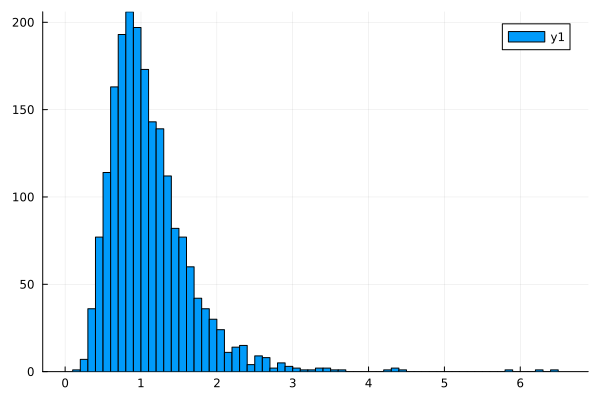

In [16]:
target = LogNormal(0, 0.45)
rng = MersenneTwister(20261014)
sample = rand(rng, target, 2_000)
histogram(sample)

The shifted cumulants $\bm\kappa$ described earlier are propagated into shifted moments $\bm\mu$ with Faà di Bruno's recurrence, then transformed into Laguerre coefficients $\bm a$. The objective is the unweighted sum of squared residuals across those coefficients: since Laguerre's basis is orthnormal, this is approximating the L2 distance between the densities. 

In [17]:
function sample_laguerre_coefficients(x, m)
    T = eltype(x)
    z = 2 .* x
    w = exp.(.-x)
    
    previous = ones(T, length(z))
    current = one(T) .- z
    a = Vector{T}(undef, m)
    a[1] = sqrt(T(2)) * mean(w)
    a[2] = sqrt(T(2)) * mean(w .* current)
    
    for i in 1:(m - 2)
        next = ((T(2i + 1) .- z) .* current .- i .* previous) ./ (i + 1)
        a[i + 2] = sqrt(T(2)) * mean(w .* next)
        previous, current = current, next
    end

    return a
end

function laguerre_transform(::Type{T}, m) where {T}
    L = zeros(T, m, m)
    for i in 0:(m - 1)
        for j in 0:i
            b = binomial(big(i), big(j))
            L[i + 1, j + 1] = T(b) * T((-2)^j) / T(factorial(big(j)))
        end
    end
    return L
end

function gamma_laguerre_coefficients(α, θ, m, B, L)
    T = eltype(α)
    η = θ ./ (one(T) .+ θ)
    κ = Vector{T}(undef, m)
    κ[1] = -sum(α .* log.(one(T) .+ θ))

    for k in 1:(m - 1)
        factorial_term = T(factorial(big(k - 1)))
        κ[k + 1] = factorial_term * sum(α .* η .^ k)
    end

    μ = exp_derivatives(κ, B, exp(κ[1]))
    a = L * μ
    a .*= sqrt(T(2))

    return a
end


gamma_laguerre_coefficients (generic function with 1 method)

We now have the necessary tools to implement the problem : 

In [30]:
M = 30 # number of gammas in the convolution
K = 70 # number of laguerre coefficients used for the loss. 
B = binomial_table(BigFloat, K)
L = laguerre_transform(BigFloat, K)
target_a = sample_laguerre_coefficients(sample, K)

function loss(log_parameters; tga=target_a, Bmat=B, Lmat=L)
    T = eltype(log_parameters)
    m = length(log_parameters) ÷ 2
    parameters = exp.(log_parameters)
    α, θ = parameters[1:m], parameters[(m + 1):end]
    proposed_a = gamma_laguerre_coefficients(α, θ, K, T.(Bmat), T.(Lmat))
    residuals = proposed_a .- T.(tga)
    return sum(residuals .^ 2)
end


loss (generic function with 1 method)

### Which fitting procedure to find the minimum ?

Our 30 gamma components have 60 unknowns: 30 shapes and 30 scales. We fit 70 empirical Laguerre coefficients (degrees 0 through 69) from the lognormal sample, giving ten more coefficients than parameters. The problem is thus overdetermined a bit. 

**Think:** Is the problem convex ? Non-convex ? How nice will the derivtives be ? Hint: look at the Faa Di Bruno formula ;)

### Which precision is required ?

A good way to decide which precision is required is simply to probe the loss at random parameters. The following table compares the loss at one fixed set of parameters, in a real application you would use a bit more. BigFloat at 256-bit precision is the reference; timing and allocations cover only the loss evaluation, not conversion of the probe parameters.

In [31]:
probe_parameters = vcat(fill(log(1.0), M), fill(log(0.3), M))
probe_types = (Float64x1, Float64x2, Float64x3, Float64x4, BigFloat)
probe_names = ("Float64x1", "Float64x2", "Float64x3", "Float64x4", "BigFloat")

probe_reference = setprecision(256) do
    loss(BigFloat.(probe_parameters))
end

probe_results = NamedTuple[]
for (T, name) in zip(probe_types, probe_names)
    parameters = T.(probe_parameters)
    value = loss(parameters)
    trial = @benchmark loss($parameters) samples=20 evals=1
    estimate = median(trial)
    push!(probe_results,
          (type=name, value=@sprintf("%.8e", Float64(value)),
           abs_error=@sprintf("%.8e", Float64(abs(BigFloat(value) - probe_reference))),
           time_us=@sprintf("%.2f", estimate.time / 1e3),
           memory_KiB=@sprintf("%.2f", estimate.memory / 1024),
           allocations=estimate.allocs))
end

probe_table_data = hcat(
    [row.type for row in probe_results],
    [row.value for row in probe_results],
    [row.abs_error for row in probe_results],
    [row.time_us for row in probe_results],
    [row.memory_KiB for row in probe_results],
    [row.allocations for row in probe_results],
)
pretty_table(probe_table_data;
    column_labels=["Type", "Loss value", "Absolute error vs BigFloat", "Median time (μs)", "Memory (KiB)", "Allocations"],
    backend=:html)

Type,Loss value,Absolute error vs BigFloat,Median time (μs),Memory (KiB),Allocations
Float64x1,3.79930577e+14,3.76220144e+14,1741.85,538.55,6353
Float64x2,3.71043334e+12,1.70288956e-03,2315.25,637.57,6353
Float64x3,3.71043334e+12,3.07117222e-20,3213.40,739.33,6353
Float64x4,3.71043334e+12,3.71102862e-35,6448.95,832.43,6358
BigFloat,3.71043334e+12,0.00000000e+00,4732.35,1780.55,22950


**Think:** From these results and ht eprevious timings we observed, which number types would you use to minimise this loss ? 

### Let's fit the model

In [ ]:
lower_bounds = log(0.00001) .* ones(2M)
upper_bounds = log(1000) .* ones(2M)
bounds = [lower_bounds'; upper_bounds']

loss_x3(log_parameters) = loss(Float64x3.(log_parameters))

algo = PSO(N=32, options=Options(iterations=100, seed=41, f_tol=-1.0, f_tol_rel=0.0))
result = optimize(loss_x3, bounds, algo)

log_parameters = minimizer(result)
parameters = exp.(log_parameters)
α_fit = parameters[1:M]
θ_fit = parameters[(M + 1):end]

result

### Distribution-level check

The coefficient loss is not, by itself, evidence that the fitted distribution is adequate. We independently simulate sums from the fitted gamma components and compare their histogram with the lognormal sample on a logarithmic density scale. This visual check tests the overall shape, including the right tail.

In [29]:
check_rng = MersenneTwister(20261015)
simulated_sum = zeros(10_000)
for i in eachindex(α_fit)
    simulated_sum .+= rand(check_rng, Gamma(α_fit[i], θ_fit[i]), 10_000)
end

histogram(sample; normalize=:pdf, xscale=:log
    label="LogNormal sample", alpha=0.45, xlabel="x (log scale)", ylabel="Density (log scale)",
    title="Independent sample check (common range)")
histogram!(simulated_sum; normalize=:pdf, label="Fitted gamma sum", alpha=0.45)

Base.Meta.ParseError: ParseError:
# Error @ c:\Users\lrnv\Documents\anf_frejus_julia\jl_notebook_cell_df34fa98e69747e1a8f8a730347b8e2f_Y105sZmlsZQ==.jl:7:46

histogram(sample; normalize=:pdf, xscale=:log
#                                            └ ── Expected `)` or `,`

# Synthesis · From arithmetic to scientific decisions

### Numerical correctness

Even when algorithms are exect, computational arithmetic never is. The rational calculation confirms the recurrence's exact result; `Float64` and the MultiFloats show how finite precision changes it.

### Generic programming

Multiple dispatch separates the algorithm, number representation, and execution strategy. This separation is useful only when conversions and promotions respect it. BigFloat's system to fit precision is not very efficient, since it is not carried by the type and thus requires allocations. On the other hand, MultiFloat is a much more julian alternative, and it can be much faster in certain circonstances. 

### Scientific validation

The lognormal-to-gamma experiment fits 70 Laguerre coefficients with 60 parameters. A low coefficient loss is only one diagnostic: inspect the independent simulated-sum histogram and quantiles before calling the fitted distribution adequate. In this run, PSO reaches its 80-iteration limit, 32 parameters sit at bounds, and the fitted mean is about 291 times the target mean. The optimizer has not found an adequate fit; treat the result as a failure case, not as a successful scientific estimate.

The fixed-probe precision table also shows that Float64 can corrupt the objective by more than $10^{12}$. Agreement at a fitted point does not establish global reliability.

> A `T` does not make code generic. A respected numerical contract does.

# Appendix · derivation, environment, sources

## Deriving the recurrence

Differentiate $M=\exp(K)$ once: $M'=MK'$. Differentiate repeatedly and apply Leibniz:

$$M^{(n)}=(MK')^{(n-1)}=\sum_{k=0}^{n-1}\binom{n-1}{k}M^{(k)}K^{(n-k)}.$$

## Why the combinatorics are exact

If factorials and binomials were generated through correlated floating-point recurrences, their rounding errors could cancel each other and hide the instability. The setup constructs each coefficient as an exact integer, converts it independently into `T`, and then performs the recurrence entirely in `T`. Setup is excluded from the timed kernel.

## Environment

The experiments use Julia 1.13.0, MultiFloats 3.3.2, and BenchmarkTools 1.8.0. `Manifest.toml` records the resolved environment. Benchmark timings depend on hardware, so compare measurements from the same machine.

## Sources

- [MultiFloats.jl](https://github.com/dzhang314/MultiFloats.jl)
- [TaylorDiff.jl](https://github.com/JuliaDiff/TaylorDiff.jl)
- [TaylorSeries.jl documentation](https://juliadiff.org/TaylorSeries.jl/stable/)
- F. M. Miatto, [Recursive multivariate derivatives of $e^{f(x_1,\ldots,x_n)}$](https://arxiv.org/abs/1911.11722)
- Julia manual: [arbitrary precision arithmetic](https://docs.julialang.org/en/v1/manual/integers-and-floating-point-numbers/)

In [ ]:
@testset "Faà di Bruno recurrence" begin
    κ = log1p_derivatives(BigFloat, 10)
    μ = exp_derivatives(κ, one(BigFloat))

    @test μ[1] == 1
    @test μ[2] == 1
    @test all(iszero, μ[3:end])
end

@testset "exact rational arithmetic" begin
    values = cancellation_experiment(Rational{BigInt}, 60)

    @test first_nonzero_order(values) === nothing
    @test all(iszero, values[3:end])
end

@testset "precision ladder" begin
    types = (Float64x1, Float64x2, Float64x3, Float64x4)
    failures = map(type -> first_nonzero_order(cancellation_experiment(type, 70)), types)

    @test failures == (29, 38, 52, 62)
end

@testset "controlled cancellation" begin
    values = cancellation_experiment(Float64, 60)

    @test values[1:2] == [1.0, 1.0]
    @test first_nonzero_order(values) !== nothing
    @test any(!iszero, values[3:end])
end

@testset "input validation" begin
    @test_throws ArgumentError log1p_derivatives(Float64, -1)
end

@testset "30-gamma, 70-coefficient objective" begin
    @test M == 30
    @test K == 70
    @test K > 2M
    @test length(target_a) == K
    @test eltype(bounds) === Float64
    @test length(probe_results) == 5
    @test map(row -> row.type, probe_results) == ["Float64x1", "Float64x2", "Float64x3", "Float64x4", "BigFloat"]
    @test all(row -> isfinite(parse(Float64, row.value)) && isfinite(parse(Float64, row.abs_error)), probe_results)
    @test parse(Float64, probe_results[5].abs_error) == 0
    @test all(row -> row.allocations >= 0 && parse(Float64, row.time_us) > 0, probe_results)
    @test loss(Float64x4.(probe_parameters)) isa Float64x4
    @test result.iteration == 80
end